In [1]:
import numpy as np
import random
from tqdm import tqdm
from itertools import cycle, count
import gym
from RLHelper import *

# 시차 학습 알고리즘

In [2]:
def decay_schedule(init_alpha, min_alpha, alpha_decay_ratio, n_episodes):
    decay_steps = int(n_episodes * alpha_decay_ratio)
    alphas = np.linspace(init_alpha, min_alpha, decay_steps)
    
    # 나머지 에피소드 동안 min_alpha 유지
    if decay_steps < n_episodes:
        alphas = np.concatenate((alphas, np.full(n_episodes - decay_steps, min_alpha)))
    return alphas

In [3]:
def td(pi, env, gamma=1.0,  # 정책, 환경, 감마(할인율)
       init_alpha=0.5, min_alpha=0.01, alpha_decay_ratio=0.5,
       # 알파(학습계수): 초기값, 최종값, 감가비율
       n_episodes=500):  # 에피소드 수
    """
    pi: 정책 함수, 주어진 상태에서 어떤 행동을 취할지를 결정합니다.
    env: 강화 학습 환경, 예를 들어 OpenAI Gym 환경.
    gamma: 할인율, 미래 보상의 현재 가치를 결정하는 파라미터.
    init_alpha: 초기 학습률.
    min_alpha: 최소 학습률.
    alpha_decay_ratio: 학습률이 감소하는 비율.
    n_episodes: 학습에 사용할 전체 에피소드 수
    """
    nS = env.observation_space.n  # 상태 수
    V = np.zeros(nS, dtype=np.float64)  # 상태-가치 함수 초기화
    
    # 오프라인 분석(에피소드 당 가치 함수, 타겟(리턴) 값)을 위한 변수 초기화
    V_track = np.zeros((n_episodes, nS), dtype=np.float64)
    targets = {state: [] for state in range(nS)}
    
    # 에피소드마다 지수적 감가되는 알파(학습계수) 값을 한 번에 계산
    alphas = decay_schedule(init_alpha, min_alpha, alpha_decay_ratio, n_episodes)

    ##실제 학습 시작
    # 에피소드 당 반복
    for e in tqdm(range(n_episodes), leave=False):
        state, done = env.reset(), False  # 상태 초기화
        if isinstance(state, tuple):
            state = state[0]
        
        # 에피소드의 종료 시까지 반복
        while not done:
            action = pi(state)  # 해당 정책의 행동 선택
            next_state, reward, done, truncated, info = env.step(action)  # 행동 수행 후 다음 상태, 보상 수집
            done = done or truncated  # `done`과 `truncated` 중 하나라도 True면 에피소드 종료
            if isinstance(next_state, tuple):
                next_state = next_state[0]
            
            # 가치 함수 갱신
            td_target = reward + gamma * V[next_state] * (not done)  # TD 타겟 계산
            targets[state].append(td_target)
            td_error = td_target - V[state]  # TD 에러 계산
            V[state] = V[state] + alphas[e] * td_error  # 상태 갱신
            
            state = next_state
        
        V_track[e] = V
    
    return V, V_track, targets  # 가치 함수 리턴

>> 참 상태-가치 함수: 동적 계획법 정책 평가
상태-가치함수:
| 00  0.542 | 01  0.499 | 02  0.471 | 03  0.457 |
| 04  0.558 |           | 06  0.358 |           |
| 08  0.592 | 09  0.643 | 10  0.615 |           |
|           | 13  0.742 | 14  0.863 |           |

정책:
| 00      < | 01      ^ | 02      ^ | 03      ^ |
| 04      < |           | 06      < |           |
| 08      ^ | 09      v | 10      < |           |
|           | 13      > | 14      v |           |
성공 확률 1.00%. 평균 리턴 값 0.7700.


All seeds: 100%|█████████████████████████████████████████████████████████████████████████| 5/5 [00:10<00:00,  2.13s/it]


>> 시차 학습
상태-가치함수:
| 00  0.501 | 01  0.456 | 02   0.42 | 03  0.402 |
| 04  0.521 |           | 06  0.339 |           |
| 08  0.561 | 09  0.616 | 10  0.599 |           |
|           | 13  0.712 | 14   0.84 |           |

State-value function errors:
| 00 -0.041 | 01 -0.043 | 02 -0.051 | 03 -0.055 |
| 04 -0.037 |           | 06 -0.019 |           |
| 08 -0.031 | 09 -0.027 | 10 -0.017 |           |
|           | 13  -0.03 | 14 -0.022 |           |
RMSE: 0.0298


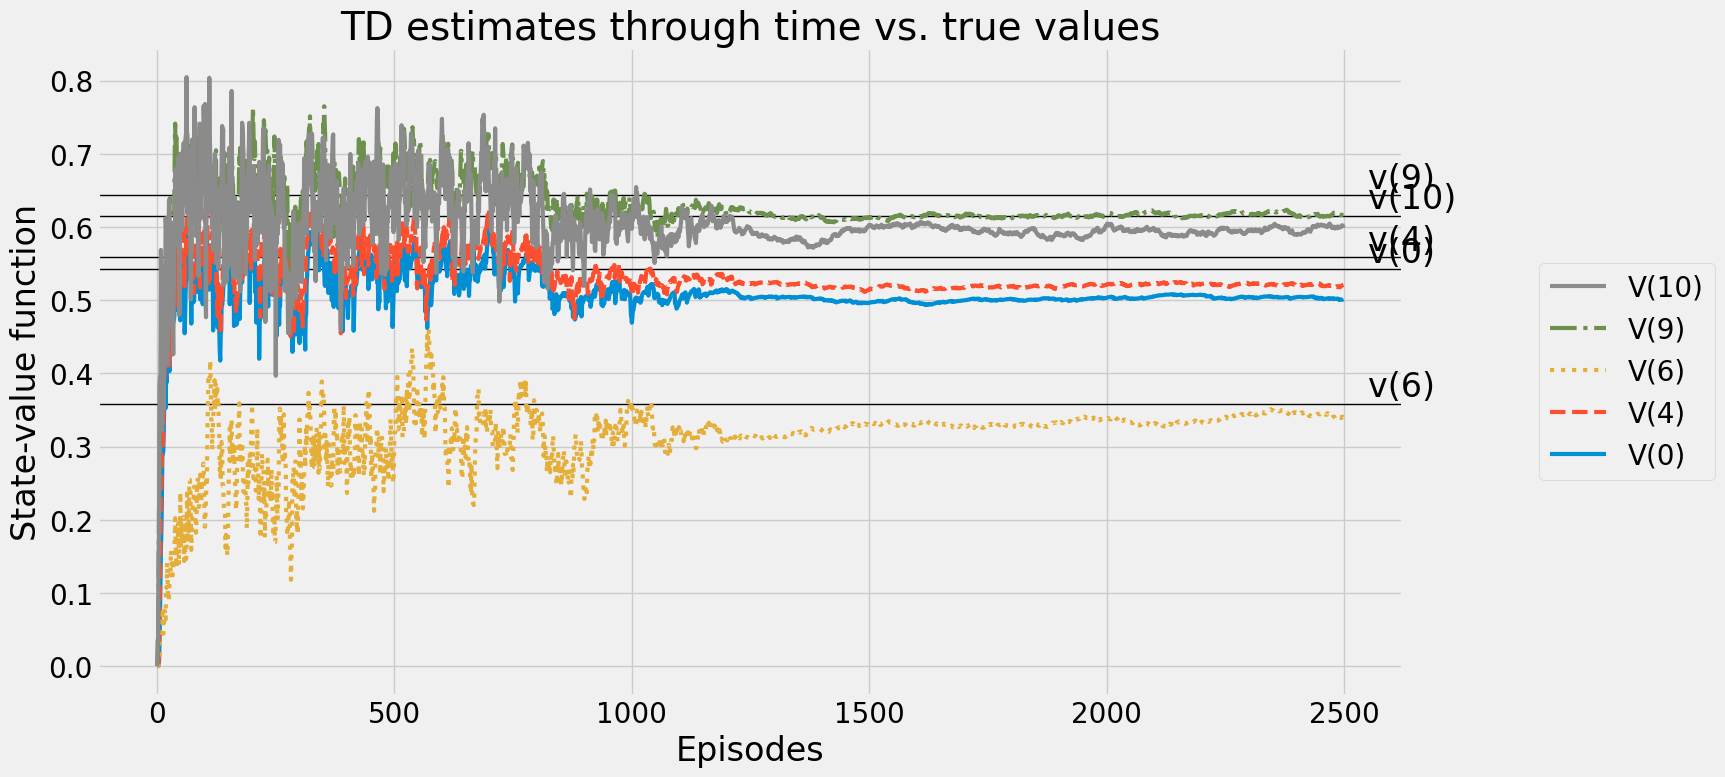

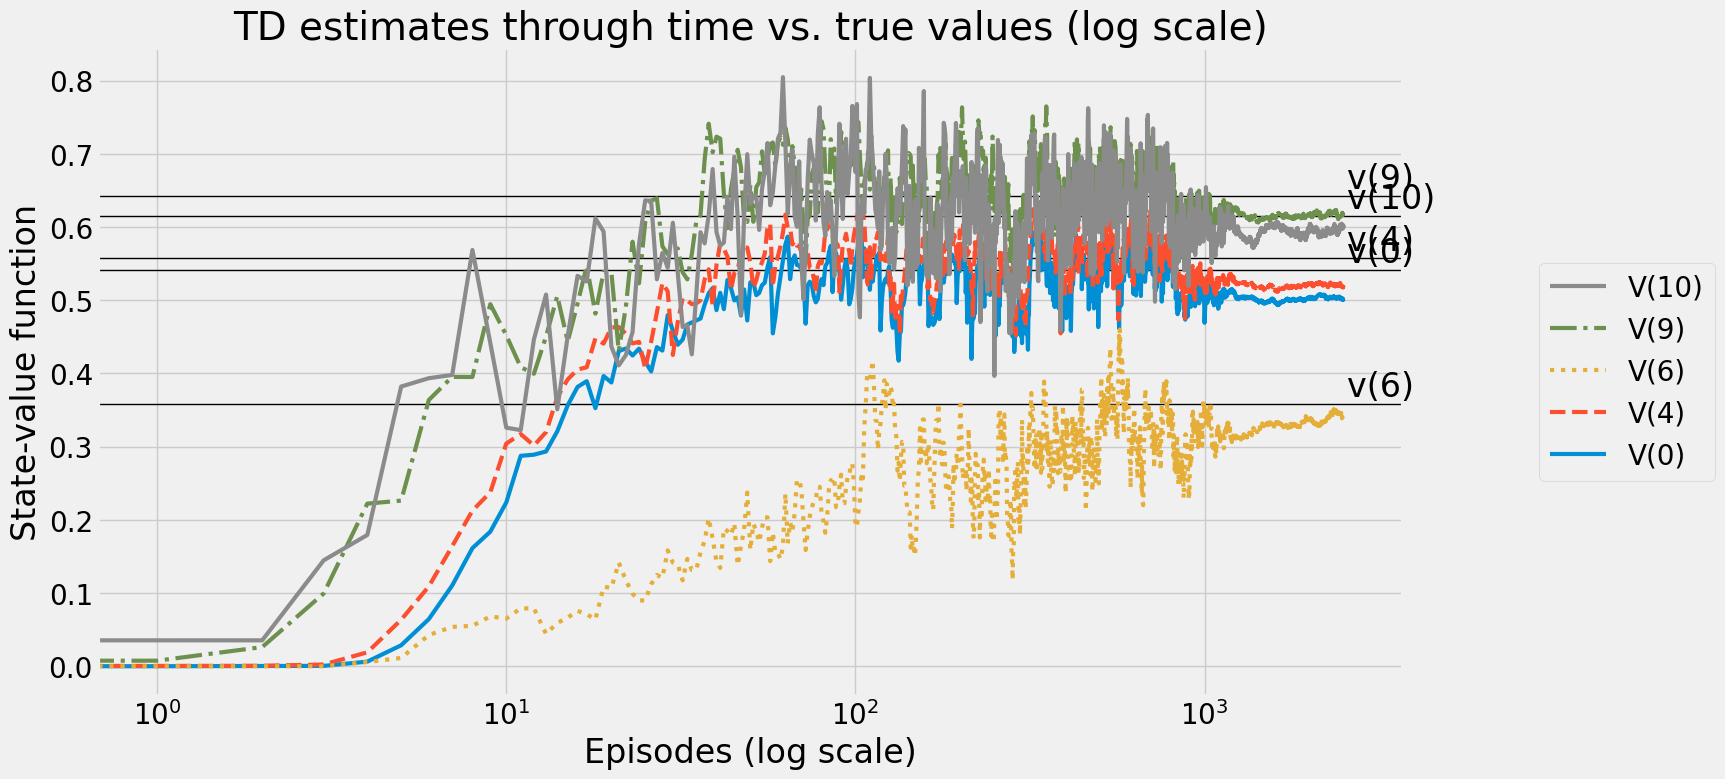

In [4]:
## 프로즌레이크 환경 생성
env = gym.make('FrozenLake-v1')

# 파라미터 초기화
goal_state = 15
gamma = 0.99
n_episodes = 2500
P = env.env.P  # 상태 전이 확률

## 샘플 정책 생성
LEFT, DOWN, RIGHT, UP = range(4)
pi = lambda s: {
    0: LEFT, 1: UP, 2: UP, 3: UP,
    4: LEFT, 5: LEFT, 6: LEFT, 7: LEFT,
    8: UP, 9: DOWN, 10: LEFT, 11: LEFT,
    12: LEFT, 13: RIGHT, 14: DOWN, 15: LEFT
}[s]

## 참 상태-가치 함수 계산: 동적 계획법의 정책 평가
V_true = policy_evaluation(pi, P, gamma=gamma)

# 가치 함수, 정책, 성공 확률 출력
print(">> 참 상태-가치 함수: 동적 계획법 정책 평가")
print_state_value_function(V_true, P)
print()
print_policy(pi, P)
print('성공 확률 {:.2f}%. 평균 리턴 값 {:.4f}.'.format(
    probability_success(env, pi, goal_state=goal_state), 
    mean_return(env, gamma, pi)))

## 시차 학습
# 각기 다른 시드 값으로 5번 수행 후의 상태-가치 함수 평균 값
SEEDS = (12, 34, 56, 78, 90)
V_tds, V_track_tds = [], []  # 5번 수행 상태-가치 함수 임시 저장

# 5개 시드에 대해 TD 반복 수행
for seed in tqdm(SEEDS, desc='All seeds', leave=True):
    random.seed(seed)
    np.random.seed(seed)
    env.reset(seed=seed)
    # 시차 학습 수행
    V_td, V_track_td, targets_td = td(pi, env, gamma=gamma, n_episodes=n_episodes)
    # 상태-가치 함수 저장
    V_tds.append(V_td)
    V_track_tds.append(V_track_td)

# 5개의 상태-가치 함수 평균 값 계산
V_td = np.mean(V_tds, axis=0)
V_track_td = np.mean(V_track_tds, axis=0)
del V_tds
del V_track_tds

# 가치 함수, 가치 함수 에러, 평균 제곱근 오차 출력
print(">> 시차 학습")
print_state_value_function(V_td, P)
print()
print_state_value_function(V_td - V_true, P, title='State-value function errors:')
print('RMSE:', rmse(V_td, V_true))

## 에피소드 진행에 따른 TD 상태-가치 함수 값 추정 그래프, 5개 상태의 선택
# 에피소드가 진행함에 따라 참 값으로 수렴
plot_value_function('TD estimates through time vs. true values', V_track_td, V_true, log=False)
# x축을 로그 스케일로 변환한 그래프
plot_value_function('TD estimates through time vs. true values (log scale)', V_track_td, V_true, log=True)
